# 05 — Colonisation model: where will the toad be in year X?

Notebooks 02–04 answered separate questions: how fast the front moves, where the climate is suitable, and how much the niche can expand. This notebook combines them into one model that answers:

> **What is the probability that each 25 km cell is occupied by the cane toad in year X?**

The invasion front, the occupied area and their uncertainty all follow from that.

### The model

For every year *t* and every cell **not yet occupied**, we ask: is the cell colonised (first toad record) in year *t*? The response is binary, and each cell stays "at risk" until it is colonised. This is a **discrete-time survival model**: a logistic regression on a cell × year table, where cells never colonised are *censored* (we only know their colonisation happens after the last year, if ever).

| Predictor | Meaning |
|---|---|
| Distance to the nearest occupied cell (log) | Toads arrive from nearby. The log lets rare long jumps happen (e.g. toads transported by people) |
| Occupied cells within 50 km and within 100 km | Local "pressure" of the invasion |
| Climate suitability (logit) | From notebooks 03–04, under two scenarios |

**Two suitability scenarios** (decided in notebook 04):
- **Observed niche:** climate model trained on Australian records only. Conservative.
- **Expanded niche:** climate model trained on native + Australian records. Permissive.

**Validation:** a backtest with no leakage. Everything (suitability *and* colonisation model) is trained with data up to 2015, the invasion is simulated year by year to 2025, and the result is compared with what actually happened.

In [1]:
import sys
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))
from colonization import CANDIDATE_FEATURES, FEATURES, cell_year_table, simulate
from download import download_australia_outline
from environment import BIOCLIM_VARIABLES, environmental_grid
from front import AUSTRALIAN_ALBERS, records_to_cells
from native import native_training_cells

FIGURES = PROJECT_ROOT / "figures"
PROCESSED = PROJECT_ROOT / "data" / "processed"
CELL_SIZE_M = 25_000
CLIMATE = list(BIOCLIM_VARIABLES.values())
TRAIN_START = 1990

cells = environmental_grid(CELL_SIZE_M)
first_detection = records_to_cells(
    pd.read_csv(PROCESSED / "rhinella_marina_clean.csv"), CELL_SIZE_M
)[["cx", "cy", "first_year"]]
cells = cells.merge(first_detection, how="left", on=["cx", "cy"])
cells["first_year"] = cells["first_year"].fillna(np.inf)
cells["x_km"] = (cells["cx"] + 0.5) * CELL_SIZE_M / 1000
cells["y_km"] = (cells["cy"] + 0.5) * CELL_SIZE_M / 1000
native = native_training_cells(CELL_SIZE_M)
print(f"{len(cells):,} Australian cells, {np.isfinite(cells['first_year']).sum():,} occupied by 2025")

12,312 Australian cells, 1,310 occupied by 2025


## 1. Suitability without leakage

For the backtest, the suitability models only see Australian presences up to the cut-off year. Otherwise they would "know" where toads arrived after 2015.

In [2]:
def climate_model():
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LogisticRegression(max_iter=5000))


def suitability(scenario: str, cutoff_year: int) -> np.ndarray:
    australia = cells[CLIMATE].assign(toad=(cells["first_year"] <= cutoff_year).astype(int))
    training = australia if scenario == "observed niche" else pd.concat([native[CLIMATE + ["toad"]], australia])
    return climate_model().fit(training[CLIMATE], training["toad"]).predict_proba(cells[CLIMATE])[:, 1]


SCENARIOS = ["observed niche", "expanded niche"]
suitability_2015 = {scenario: suitability(scenario, 2015) for scenario in SCENARIOS}

## 2. The cell × year table

In [3]:
train_table = {s: cell_year_table(cells, suitability_2015[s], range(TRAIN_START, 2016)) for s in SCENARIOS}
test_table = {s: cell_year_table(cells, suitability_2015[s], range(2016, 2026)) for s in SCENARIOS}

example = train_table["observed niche"]
print(f"Training: {len(example):,} cell-years, {example['colonised'].sum()} colonisations "
      f"({100 * example['colonised'].mean():.2f}% per cell-year)")
print(f"Test: {len(test_table['observed niche']):,} cell-years, {test_table['observed niche']['colonised'].sum()} colonisations")
example.sample(5, random_state=0)

Training: 301,695 cell-years, 467 colonisations (0.15% per cell-year)
Test: 112,071 cell-years, 313 colonisations


,log_distance_km,neighbours_50km,neighbours_100km,recent_neighbours_100km,suitability_logit,colonised,year,cell
16669,4.645137,0,0,0,-4.019475,0,1991,4938
159533,7.321189,0,0,0,-6.438003,0,2003,7432
184489,6.094236,0,0,0,-5.686302,0,2005,9297
180710,5.030889,0,0,0,-7.209783,0,2005,5237
41192,7.062355,0,0,0,-6.497123,0,1993,5963


Colonisations are **rare events** (well under 1% of cell-years), which is typical for survival data. Most cells are far from any toad and have almost zero probability.

## 3. Comparing model variants in the backtest

Each variant is trained on 1990–2015 and evaluated on 2016–2025 in two ways:

- **One-step AUC:** for each test year, given the *true* occupancy of the previous year, how well does the model rank which cells get colonised?
- **Multi-step simulation:** starting from the 2015 occupancy, the model simulates its own invasion year by year until 2025 (Monte Carlo, 50 runs). This is the real forecasting test, because errors accumulate. We compare:
  - the AUC of the simulated probability of being occupied by 2025, among cells empty in 2015;
  - the number of newly colonised cells;
  - the position of the western front in 2025 (3rd westernmost occupied cell west of 141°E, km in Australian Albers).

In [4]:
N_RUNS_BACKTEST = 50
west = (cells["lon"] < 141).to_numpy()
occupied_2015 = (cells["first_year"] <= 2015).to_numpy()
occupied_2025 = (cells["first_year"] <= 2025).to_numpy()
x_km = cells["x_km"].to_numpy()


def western_front(occupied: np.ndarray) -> float:
    return np.sort(x_km[occupied & west])[2]


VARIANTS = {
    "distance only": (lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                      [f for f in FEATURES if f != "suitability_logit"]),
    "distance + suitability (main)": (lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), FEATURES),
    "+ interactions": (lambda: make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), LogisticRegression(max_iter=5000)), FEATURES),
    "+ recent colonisations nearby": (lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), CANDIDATE_FEATURES),
    "LightGBM": (lambda: lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, verbose=-1, random_state=0), FEATURES),
}


def evaluate(scenario, factory, features):
    train, test = train_table[scenario], test_table[scenario]
    model = factory().fit(train[features], train["colonised"])
    one_step = roc_auc_score(test["colonised"], model.predict_proba(test[features])[:, 1])
    simulated = simulate(model, cells, suitability_2015[scenario], 2015, range(2016, 2026),
                         n_runs=N_RUNS_BACKTEST, features=features)
    occupied_sim = simulated <= 2025
    fronts = np.array([western_front(run) for run in occupied_sim])
    return model, occupied_sim, {
        "one-step AUC": one_step,
        "multi-step AUC": roc_auc_score(occupied_2025[~occupied_2015], occupied_sim.mean(axis=0)[~occupied_2015]),
        "new cells (simulated median)": np.median(occupied_sim.sum(axis=1)) - occupied_2015.sum(),
        "western front error 2025 (km)": np.median(fronts) - western_front(occupied_2025),
        "front 90% interval (km)": f"{np.percentile(fronts, 5):.0f} to {np.percentile(fronts, 95):.0f}",
    }


backtest = {}
backtest_runs = {}
for name, (factory, features) in VARIANTS.items():
    model, runs, metrics = evaluate("observed niche", factory, features)
    backtest[("observed niche", name)] = metrics
    backtest_runs[("observed niche", name)] = runs
model, runs, metrics = evaluate("expanded niche", *VARIANTS["distance + suitability (main)"])
backtest[("expanded niche", "distance + suitability (main)")] = metrics
backtest_runs[("expanded niche", "distance + suitability (main)")] = runs

print(f"Observed: {occupied_2025.sum() - occupied_2015.sum()} new cells; western front 2025 at {western_front(occupied_2025):.0f} km "
      f"(2015: {western_front(occupied_2015):.0f} km)")
pd.DataFrame(backtest).T.round(3)

Observed: 313 new cells; western front 2025 at -862 km (2015: -488 km)


one-step AUC multi-step AUC  \
observed niche distance only                     0.902372       0.809098   
               distance + suitability (main)     0.905717       0.829198   
               + interactions                    0.898484       0.823712   
               + recent colonisations nearby     0.911848       0.825422   
               LightGBM                          0.897894       0.835409   
expanded niche distance + suitability (main)     0.904384       0.816807   

                                             new cells (simulated median)  \
observed niche distance only                                        270.0   
               distance + suitability (main)                        186.5   
               + interactions                                       175.0   
               + recent colonisations nearby                        154.5   
               LightGBM                                             185.0   
expanded niche distance + suitability (main)                        219.0   

                                             western front error 2025 (km)  \
observed niche distance only                                        -200.0   
               distance + suitability (main)                          12.5   
               + interactions                                        225.0   
               + recent colonisations nearby                         175.0   
               LightGBM                                              225.0   
expanded niche distance + suitability (main)                         112.5   

                                             front 90% interval (km)  
observed niche distance only                           -1590 to -662  
               distance + suitability (main)           -1488 to -549  
               + interactions                           -951 to -512  
               + recent colonisations nearby           -1051 to -512  
               LightGBM                                 -788 to -562  
expanded niche distance + suitability (main)           -1206 to -560

How to read it (negative front error = the simulated front ends up further west than observed; positive = it lags behind):

- **All variants rank cells similarly well one step ahead** (AUC ≈ 0.90). Distance alone already explains most of *which* cells are colonised next.
- **The differences show up in the multi-step simulation**, especially in the position of the front. The **simple logistic model with distance + suitability** is the best: it places the 2025 western front **12.5 km** from the observed one, after a real advance of 375 km. Without suitability (distance only), the simulated front **overshoots by 200 km**: climate is what holds it back. Adding interactions, the "recent colonisations" feature or using LightGBM makes the front **lag** by 175–225 km. Same lesson as in notebook 03: more flexibility does not mean better extrapolation. The expanded-niche scenario lags by ~110 km in the backtest.
- **All variants underestimate the number of new cells** (~155–270 simulated vs 313 observed). That is not the toads; it is **survey effort**: amphibian records in ALA grew about 15-fold after 2017 (FrogID), so many cells behind the front got their *first record* in 2016–2025. The model was trained in a period with much less effort. We keep this as an explicit limitation rather than adding an effort predictor that would have to be extrapolated far outside its training range.
- The front's 90% interval is wide and skewed to the west: the log-distance term allows rare long jumps, as happens with transported toads.

## 4. What did the main model learn?

In [5]:
main_model = VARIANTS["distance + suitability (main)"][0]().fit(
    train_table["observed niche"][FEATURES], train_table["observed niche"]["colonised"]
)
coefficients = pd.Series(main_model[-1].coef_[0], index=FEATURES)
pd.DataFrame({"coefficient (per SD)": coefficients, "odds ratio (per SD)": np.exp(coefficients)}).round(2)

,coefficient (per SD),odds ratio (per SD)
log_distance_km,-1.10,0.33
neighbours_50km,0.24,1.28
neighbours_100km,-0.26,0.77
suitability_logit,1.30,3.66


Coefficients are on standardised predictors, so they are comparable: the **odds ratio** says how many times the odds of colonisation multiply when the predictor increases by one standard deviation.

- **Distance** has the strongest negative effect: cells far from toads are rarely colonised.
- **Suitability** has a strong positive effect: at the same distance, a suitable cell is much more likely to be colonised. This is the term that makes the front slow down at the Pilbara without being told to.
- The two neighbourhood counts partly cancel out (they are correlated); together they describe whether a cell is next to a dense or a sparse part of the range.

## 5. Backtest map: what the model expected in 2015 vs what happened

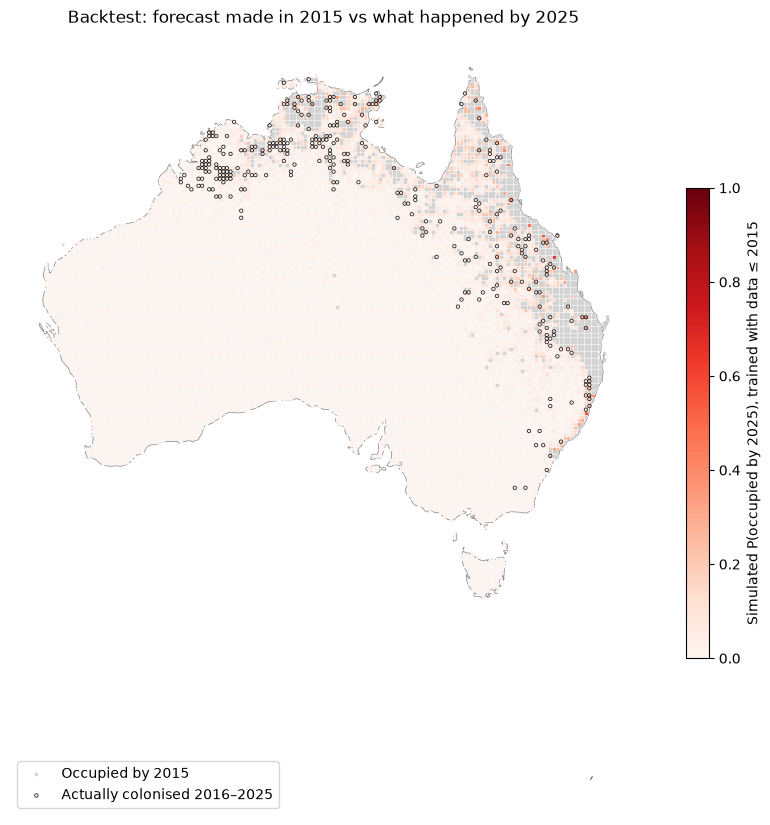

In [6]:
outline = download_australia_outline().to_crs(AUSTRALIAN_ALBERS)
x_m, y_m = x_km * 1000, cells["y_km"].to_numpy() * 1000
probability_2025 = backtest_runs[("observed niche", "distance + suitability (main)")].mean(axis=0)

fig, ax = plt.subplots(figsize=(10, 8.5))
outline.plot(ax=ax, color="whitesmoke", edgecolor="grey", linewidth=0.5)
new = ~occupied_2015
image = ax.scatter(x_m[new], y_m[new], c=probability_2025[new], cmap="Reds", s=1.6, marker="s", vmin=0, vmax=1)
ax.scatter(x_m[occupied_2015], y_m[occupied_2015], c="lightgrey", s=1.6, marker="s", label="Occupied by 2015")
colonised = occupied_2025 & ~occupied_2015
ax.scatter(x_m[colonised], y_m[colonised], facecolors="none", edgecolors="black", s=6, linewidths=0.5,
           label="Actually colonised 2016–2025")
plt.colorbar(image, ax=ax, shrink=0.6, label="Simulated P(occupied by 2025), trained with data ≤ 2015")
ax.legend(loc="lower left")
ax.set_axis_off()
ax.set_title("Backtest: forecast made in 2015 vs what happened by 2025")
plt.tight_layout()
plt.savefig(FIGURES / "05_backtest_map.png", dpi=150)

## 6. Forecast 2026–2035

Now everything is retrained with all the data up to 2025 (suitability and colonisation model) and the invasion is simulated 10 years ahead, 200 times per scenario.

⚠️ ALA records for 2025 are probably incomplete (there is a lag between observation and upload), so the starting point slightly underestimates the current range.

In [7]:
N_RUNS_FORECAST = 200
FORECAST_YEARS = range(2026, 2036)
forecasts = {}
for scenario in SCENARIOS:
    suitability_2025 = suitability(scenario, 2025)
    table = cell_year_table(cells, suitability_2025, range(TRAIN_START, 2026))
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(table[FEATURES], table["colonised"])
    forecasts[scenario] = simulate(model, cells, suitability_2025, 2025, FORECAST_YEARS, n_runs=N_RUNS_FORECAST, seed=1)

    probability = pd.DataFrame({f"p_{year}": (forecasts[scenario] <= year).mean(axis=0) for year in FORECAST_YEARS})
    output = pd.concat([cells[["cx", "cy", "lon", "lat", "first_year"]].reset_index(drop=True), probability], axis=1)
    output.to_csv(PROCESSED / f"forecast_{scenario.replace(' ', '_')}.csv", index=False)
print("Saved forecasts for notebook 06")

Saved forecasts for notebook 06


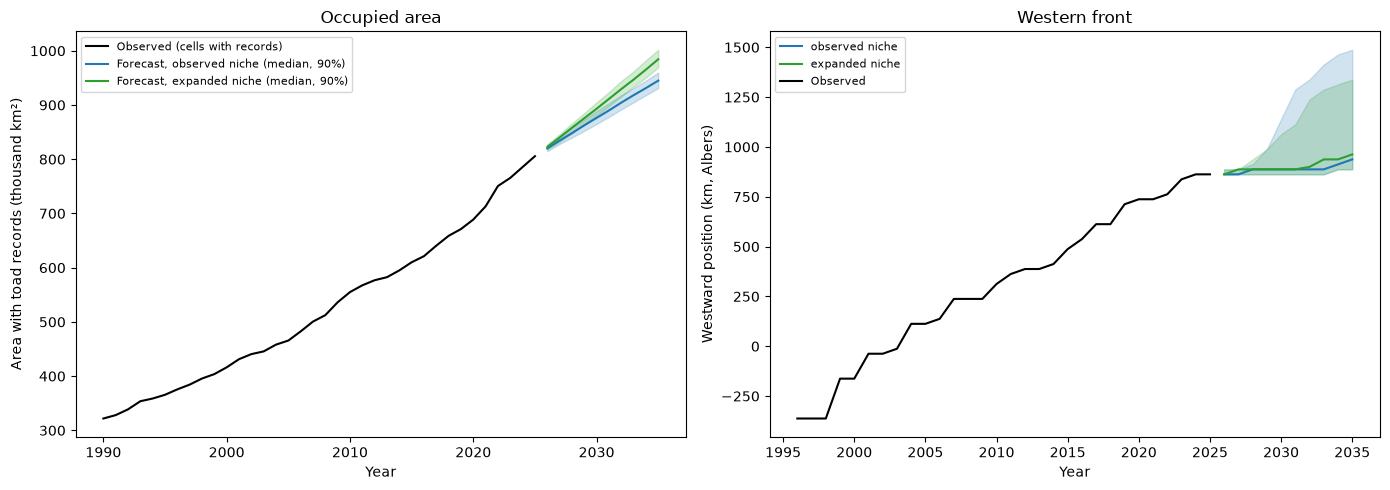

In [8]:
CELL_KM2 = (CELL_SIZE_M / 1000) ** 2
history = pd.Series({year: (cells["first_year"] <= year).sum() * CELL_KM2 for year in range(1990, 2026)})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.index, history / 1e3, color="black", label="Observed (cells with records)")
for scenario, colour in zip(SCENARIOS, ["tab:blue", "tab:green"]):
    area = np.array([(forecasts[scenario] <= year).sum(axis=1) * CELL_KM2 for year in FORECAST_YEARS]).T / 1e3
    axes[0].fill_between(FORECAST_YEARS, np.percentile(area, 5, axis=0), np.percentile(area, 95, axis=0), color=colour, alpha=0.2)
    axes[0].plot(FORECAST_YEARS, np.median(area, axis=0), color=colour, label=f"Forecast, {scenario} (median, 90%)")
    fronts = np.array([[western_front(run <= year) for run in forecasts[scenario]] for year in FORECAST_YEARS]).T
    axes[1].fill_between(FORECAST_YEARS, -np.percentile(fronts, 95, axis=0), -np.percentile(fronts, 5, axis=0), color=colour, alpha=0.2)
    axes[1].plot(FORECAST_YEARS, -np.median(fronts, axis=0), color=colour, label=scenario)
front_history = pd.Series({year: -western_front(cells["first_year"].to_numpy() <= year) for year in range(1996, 2026)})
axes[1].plot(front_history.index, front_history, color="black", label="Observed")
axes[0].set(xlabel="Year", ylabel="Area with toad records (thousand km²)", title="Occupied area")
axes[1].set(xlabel="Year", ylabel="Westward position (km, Albers)", title="Western front")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "05_forecast_area_front.png", dpi=150)

In [9]:
pilbara = (cells["lon"].between(116, 121) & cells["lat"].between(-23, -19)).to_numpy()
summary = {}
for scenario in SCENARIOS:
    for year in [2030, 2035]:
        occupied = forecasts[scenario] <= year
        area = occupied.sum(axis=1) * CELL_KM2
        front = np.array([western_front(run) for run in occupied])
        summary[(scenario, year)] = {
            "occupied area, median (thousand km²)": np.median(area) / 1e3,
            "area 90% interval": f"{np.percentile(area, 5) / 1e3:.0f} to {np.percentile(area, 95) / 1e3:.0f}",
            "western front advance vs 2025, median (km)": western_front(occupied_2025) - np.median(front),
            "P(toads recorded in the Pilbara)": occupied[:, pilbara].any(axis=1).mean(),
        }
pd.DataFrame(summary).T.round(2)

occupied area, median (thousand km²) area 90% interval  \
observed niche 2030                               876.25        865 to 889   
               2035                                945.0        931 to 960   
expanded niche 2030                              893.125        881 to 905   
               2035                              984.375       969 to 1002   

                    western front advance vs 2025, median (km)  \
observed niche 2030                                       25.0   
               2035                                       75.0   
expanded niche 2030                                       25.0   
               2035                                      100.0   

                    P(toads recorded in the Pilbara)  
observed niche 2030                            0.145  
               2035                            0.365  
expanded niche 2030                             0.19  
               2035                             0.39

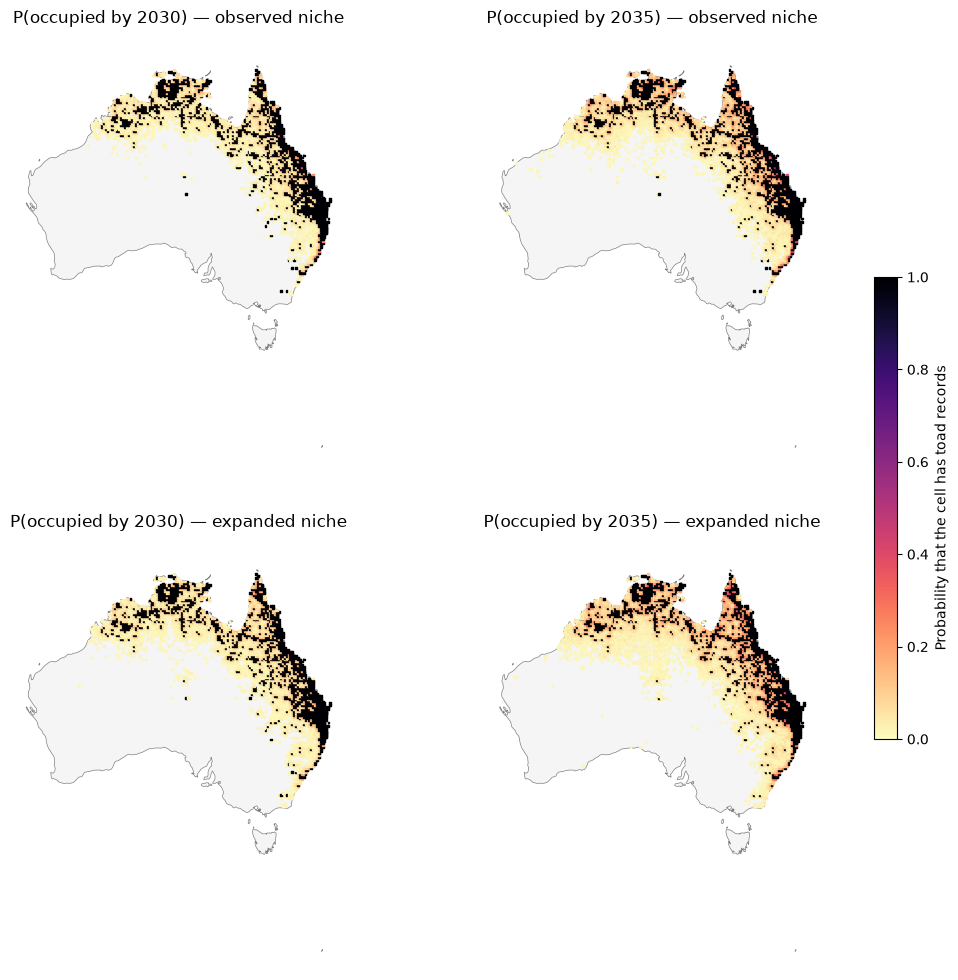

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for row, scenario in enumerate(SCENARIOS):
    for col, year in enumerate([2030, 2035]):
        ax = axes[row, col]
        outline.plot(ax=ax, color="whitesmoke", edgecolor="grey", linewidth=0.5)
        probability = (forecasts[scenario] <= year).mean(axis=0)
        shown = probability > 0.01
        image = ax.scatter(x_m[shown], y_m[shown], c=probability[shown], cmap="magma_r", s=1.6, marker="s", vmin=0, vmax=1)
        ax.set_axis_off()
        ax.set_title(f"P(occupied by {year}) — {scenario}")
fig.colorbar(image, ax=axes, shrink=0.5, label="Probability that the cell has toad records")
plt.savefig(FIGURES / "05_forecast_maps.png", dpi=150, bbox_inches="tight")

## Takeaways

- **The colonisation model reproduces the western front of 2016–2025 almost exactly** (12.5 km error after a 375 km advance) when trained with data up to 2015. It is the most credible forecast of the project.
- **It changes the answer to the main question.** The linear extrapolation of notebook 02 put the western front ~214 km further west by 2030. The colonisation model, which knows the Pilbara is unsuitable, predicts only **~25 km by 2030 and ~75–100 km by 2035**: the front is reaching the edge of suitable climate. Still, there is a **~15–20% chance of toads being recorded in the Pilbara by 2030, and ~35–40% by 2035**, through rare long jumps.
- **Simpler was better again:** distance + suitability in a plain logistic regression beat interactions, a "recent activity" feature and LightGBM in the multi-step backtest.
- **Two scenarios bracket the uncertainty about the niche:** the observed niche is conservative; the expanded niche lets the toad press further into marginal climates. The gap between them is a direct measure of how much we don't know about the toad's climatic limits.
- The full set of yearly probabilities is saved for the dynamic visualisation (notebook 06).

## Limitations
1. **"Occupied" means "recorded".** Survey effort grew about 15-fold after 2017, so the model **underestimates** how many cells get their first record, mostly behind the front. The front position is much less affected.
2. **Static climate** (1970–2000 normals); no climate change, no wet/dry year variation.
3. **No artificial water, roads or human transport** as predictors: the log-distance term only mimics long jumps statistically.
4. **The 2025 starting point is incomplete** because of the ALA upload lag.
5. **The 25 km grid** hides local habitat.